# Supplementary Figure 8: cosine similarity of the lipid-screen MGMs

Agglomerative clustering of the LV loading vectors of the ten CLAMPfull canonical ARCHS4 models (seed 123 and the nine stability seeds). Shown are the member LVs of the MGMs that survive:

1. removal of LVs flagged by the technical-noise screen,
2. complete-linkage clustering of the L2-normalised loadings at cosine similarity >= 0.5,
3. clusters represented in >= 6/10 distinct seeds,

and that are enriched for the HepG2 lipid-screen gene sets (GSEA adjusted P < 0.05). Blocks are MGMs ordered by GSEA adjusted P; LVs within a block are ordered by complete-linkage clustering.

💡 **Environment:** `clamp-analyses`

## Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from pyprojroot import here

## Inputs

In [2]:
METALV = here("output/03_model_biology/02_archs4/04_crispercas_ge4r015med/00_mgm")
OUT = here("output/99_panels/supp8")
OUT.mkdir(parents=True, exist_ok=True)
FDR = 0.05

d = np.load(METALV / "Z_all.npz", allow_pickle=True)
key = {f"{m}:{l}": i for i, (m, l) in enumerate(zip(d["models"], d["lvs"]))}
members = pd.read_csv(METALV / "cluster_members.csv")
gsea = pd.read_csv(METALV / "gsea/gsea_best.csv")
funnel = pd.read_csv(METALV / "selection/funnel.csv")
sig = gsea[gsea.padj < FDR].groupby("lv").padj.min().sort_values()
assert set(sig.index) == set(funnel[funnel.pass_gsea].metaLV)

## Selection counts

In [3]:
steps = ["pass_gsea", "pass_trait", "pass_canonical", "pass_screen_gene_top", "pass_missed_by_twas", "pass_lipid_pathway"]
counts = pd.DataFrame({"step": ["MGMs (>= 6/10 seeds)", *steps], "n_MGMs": [len(funnel), *[int(funnel[s].sum()) for s in steps]]})
print(f"LVs in the figure: {members.metaLV.isin(sig.index).sum()} from {len(sig)} MGMs")
counts

LVs in the figure: 307 from 52 MGMs


,step,n_MGMs
0,MGMs (>= 6/10 seeds),1058
1,pass_gsea,52
2,pass_trait,33
3,pass_canonical,26
4,pass_screen_gene_top,26
5,pass_missed_by_twas,23
6,pass_lipid_pathway,5


## Heatmap

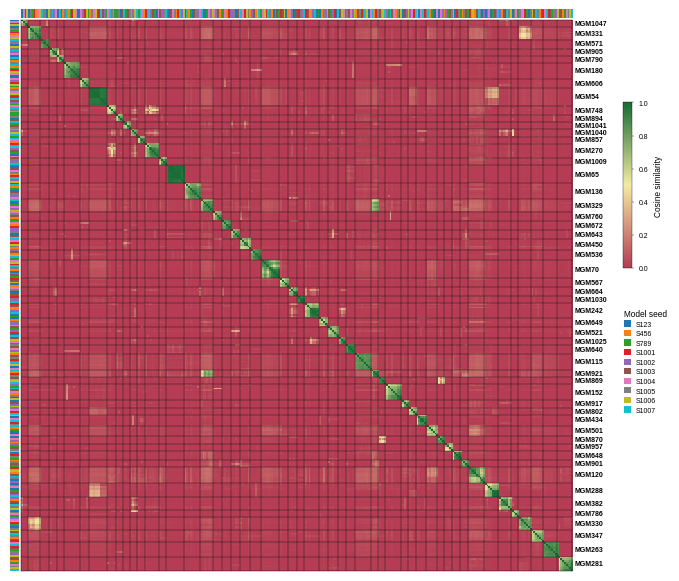

In [4]:
from matplotlib.patches import Patch
matplotlib.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "Liberation Sans"],
    "font.size": 5, "pdf.fonttype": 42, "svg.fonttype": "none", "axes.linewidth": 0.25,
})
MM = 1 / 25.4
cmap = LinearSegmentedColormap.from_list("ryg", ["#b53c54", "#f3eaa1", "#176c35"])
X = d["X"]


def unit(a):
    return a / np.linalg.norm(a, axis=1, keepdims=True)


names, blocks = [], []
for lv in sig.index:
    mm = members[members.metaLV == lv]
    ids = [key[f"{m}:{l}"] for m, l in zip(mm.model, mm.LV)]
    Y = unit(X[ids])
    if len(ids) > 2:
        order = leaves_list(linkage(squareform(np.clip(1 - Y @ Y.T, 0, 2), checks=False), method="complete"))
        ids = [ids[i] for i in order]
    names += ids
    blocks.append(len(ids))
Y = unit(X[names])
C = np.clip(Y @ Y.T, 0, 1)
n = len(names)

seeds = sorted(set(d["models"]), key=lambda s: int(s[1:]))
seed_cols = dict(zip(seeds, plt.get_cmap("tab10").colors))
seed_rgb = np.array([[seed_cols[d["models"][i]] for i in names]])

W, H = 180 * MM, 150 * MM
strip, gap, side = 2.2 * MM, 0.5 * MM, 140 * MM
x0, y0 = 4 * MM + strip + gap, 4 * MM
fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([x0 / W, y0 / H, side / W, side / H])
ax.imshow(C, cmap=cmap, norm=Normalize(0, 1), interpolation="nearest", aspect="auto")
ax.set_xticks([]); ax.set_yticks([])
top = fig.add_axes([x0 / W, (y0 + side + gap) / H, side / W, strip / H])
top.imshow(seed_rgb, aspect="auto", interpolation="nearest")
lft = fig.add_axes([(x0 - gap - strip) / W, y0 / H, strip / W, side / H])
lft.imshow(seed_rgb.transpose(1, 0, 2), aspect="auto", interpolation="nearest")
for a in (top, lft):
    a.set_axis_off()
pos = 0
for lv, b in zip(sig.index, blocks):
    ax.text(n + 1, pos + b / 2 - 0.5, lv.replace("metaLV", "MGM"), va="center", ha="left",
            fontsize=5, fontweight="bold", clip_on=False)
    pos += b
    if pos < n:
        ax.axhline(pos - 0.5, color="#111", lw=0.3)
        ax.axvline(pos - 0.5, color="#111", lw=0.3)
for a in (ax,):
    for s in a.spines.values():
        s.set_linewidth(0.3)

lx = x0 + side + 13 * MM
cax = fig.add_axes([lx / W, (y0 + side * 0.55) / H, 2.2 * MM / W, side * 0.3 / H])
cb = fig.colorbar(matplotlib.cm.ScalarMappable(Normalize(0, 1), cmap), cax=cax)
cb.set_label("Cosine similarity", fontsize=6)
cb.ax.tick_params(labelsize=5, width=0.25, length=1.5)
cb.outline.set_linewidth(0.25)
fig.legend(handles=[Patch(facecolor=seed_cols[s], label=s) for s in seeds], title="Model seed",
           loc="upper left", bbox_to_anchor=(lx / W - 0.003, (y0 + side * 0.48) / H),
           frameon=False, fontsize=5, title_fontsize=6, handlelength=1, handleheight=1,
           borderaxespad=0, labelspacing=0.3, alignment="left")
for ext, kw in [("png", {"dpi": 600}), ("pdf", {}), ("svg", {})]:
    fig.savefig(OUT / f"supp8.{ext}", facecolor="white", **kw)
plt.show()